# 01 · Exploring the data

First look at the three input files: what's in them, what's broken, and what that means for the model.

## Load the files

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (9, 4)

train = pd.read_csv("../data/train_test.csv")
val = pd.read_csv("../data/validation.csv")
dec = pd.read_csv("../data/december_chart_inputs.csv")

TARGET = "posted_rate"

## Shape, columns, missing values and date formats

In [2]:
print(train.shape, val.shape, dec.shape)
print("In train only:", set(train.columns) - set(val.columns))
print("In val only:  ", set(val.columns) - set(train.columns))

train.info()
display(train.head())
display(train.isna().sum())
display(val.isna().sum())

# Check date formats BEFORE converting
print(train["date"].str.len().value_counts())
for df in (train, val, dec):
    df["date_raw"] = df["date"]
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    print("unparseable dates:", df["date"].isna().sum())

(48000, 14) (12000, 13) (31, 7)
In train only: {'posted_rate'}
In val only:   set()
<class 'pandas.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  str    
 1   pickup        48000 non-null  str    
 2   delivery      48000 non-null  str    
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  str    
 9   weight        47700 non-null  float64
 10  date          48000 non-null  str    
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), str(5)
memory usage: 5.1 MB


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64

date
10    48000
Name: count, dtype: int64
unparseable dates: 0
unparseable dates: 0
unparseable dates: 0


## The target: `posted_rate`
Right-skewed with a long tail up to $25k, so I model the log of the rate.

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
1%         327.168800
5%         599.738500
25%       1251.555000
50%       2030.760000
75%       3330.750000
95%       4953.766500
99%       5972.834000
max      25533.000000
Name: posted_rate, dtype: float64

zero or negative: 0
skew: 1.9023948792201801


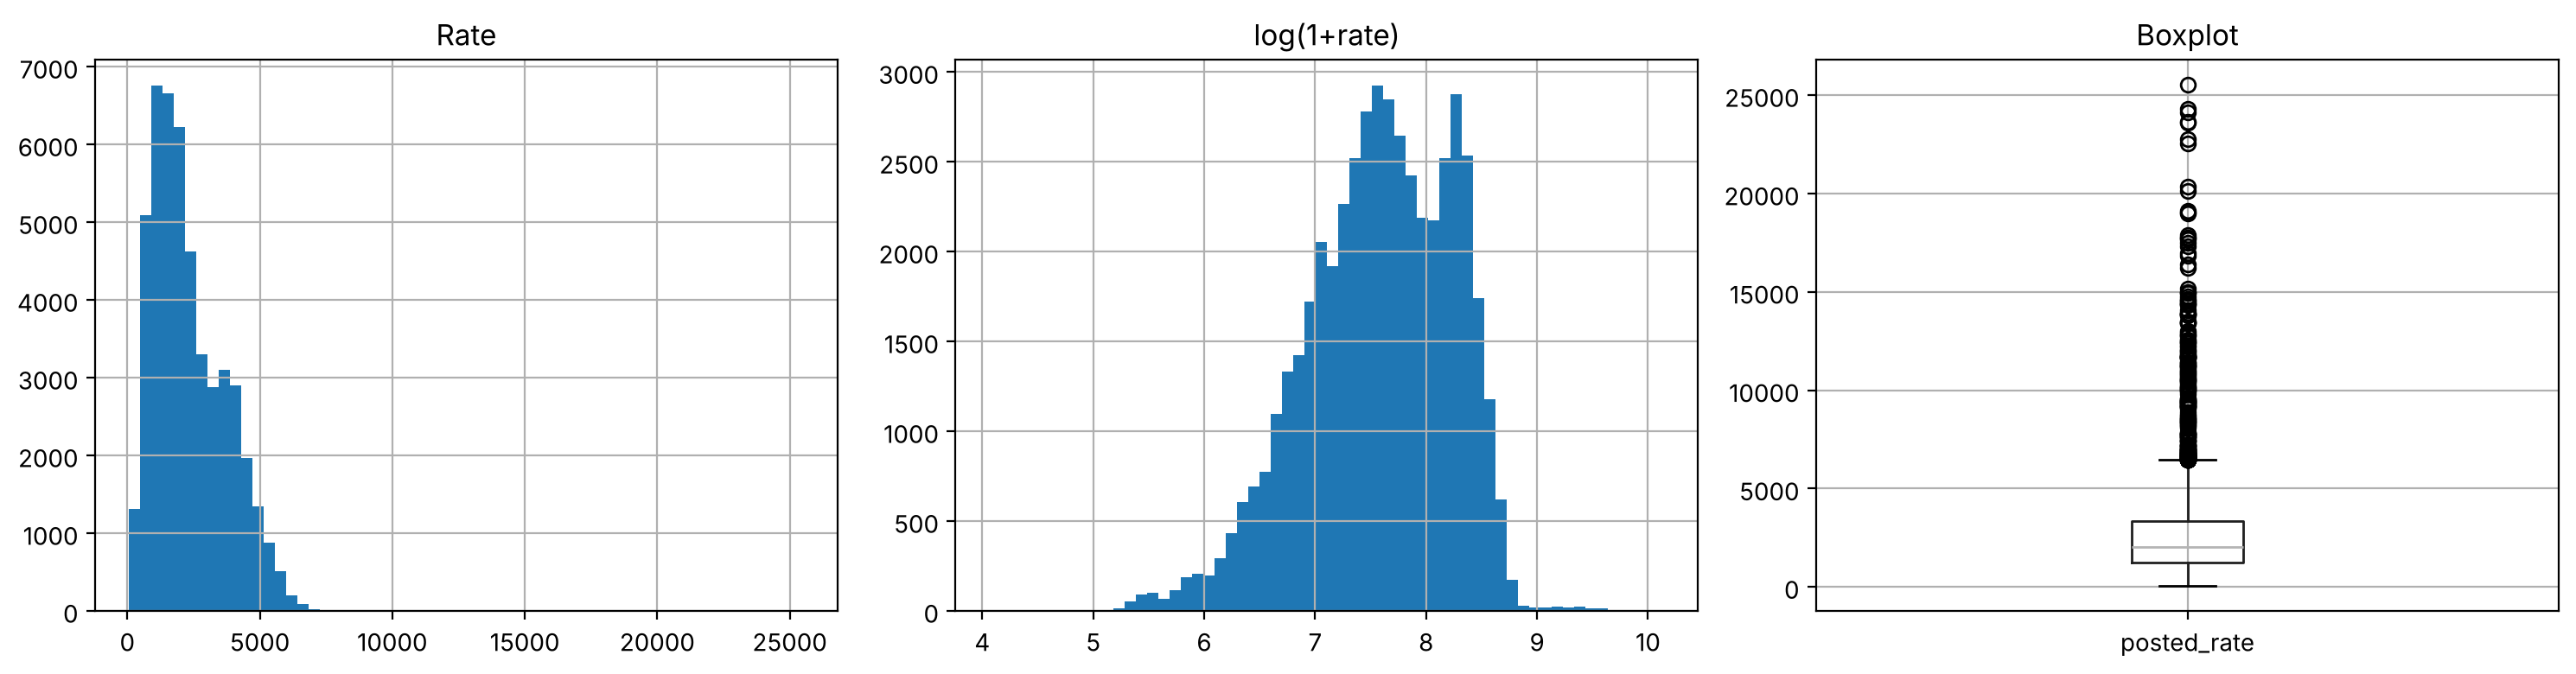

In [3]:
display(train[TARGET].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
print("zero or negative:", (train[TARGET] <= 0).sum())
print("skew:", train[TARGET].skew())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
train[TARGET].hist(bins=60, ax=ax[0]); ax[0].set_title("Rate")
np.log1p(train[TARGET].clip(lower=0)).hist(bins=60, ax=ax[1]); ax[1].set_title("log(1+rate)")
train.boxplot(column=TARGET, ax=ax[2]); ax[2].set_title("Boxplot")
plt.tight_layout(); plt.show()

## Categories, numeric columns and lanes


--- pickup: 64 unique ---


pickup
Oklahoma City    1242
Lexington        1209
Bakersfield      1193
Fort Wayne       1170
Hartford         1150
Richmond         1140
Nashville        1124
Phoenix          1121
Baton Rouge      1115
Mobile           1094
Cincinnati       1080
Shreveport       1062
Kansas City      1053
Columbia         1049
Atlanta          1029
San Antonio       972
Philadelphia      946
Los Angeles       945
Milwaukee         944
Tucson            944
Syracuse          907
Montgomery        884
Greensboro        865
Memphis           852
Charleston        848
Name: count, dtype: int64


--- delivery: 64 unique ---


delivery
Lexington        1197
Fort Wayne       1176
Baton Rouge      1167
Bakersfield      1156
Hartford         1143
Oklahoma City    1140
Richmond         1109
Atlanta          1096
Phoenix          1090
Mobile           1089
Cincinnati       1084
Columbia         1071
Nashville        1064
Tucson            997
Shreveport        983
Kansas City       980
San Antonio       965
Philadelphia      959
Los Angeles       955
Syracuse          926
Memphis           912
Montgomery        903
Grand Rapids      894
Milwaukee         859
Charleston        851
Name: count, dtype: int64


--- equipment: 3 unique ---


equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

,distance,weight,market_index,quote_signal
count,48000.000000,47700.000000,47626.000000,48000.000000
mean,1135.856654,31028.844004,1.083387,2.062468
std,728.564416,9391.440620,0.168091,0.291391
min,70.000000,-47500.000000,0.676390,0.692280
25%,550.400000,25800.000000,0.949670,1.891030
50%,953.300000,31436.500000,1.055800,2.055750
75%,1645.525000,37018.000000,1.219590,2.221685
max,3439.800000,47500.000000,1.467780,3.610350


,pickup_lat,pickup_lon,delivery_lat,delivery_lon
count,48000.000000,48000.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310
std,4.315285,13.482431,4.317199,13.476589
min,28.357650,-121.698490,28.357650,-121.698490
25%,31.986910,-98.400590,31.986910,-98.400590
50%,35.294790,-88.089150,35.294790,-87.528710
75%,39.411040,-83.285060,39.411040,-83.285060
max,44.302960,-69.500000,44.302960,-69.500000


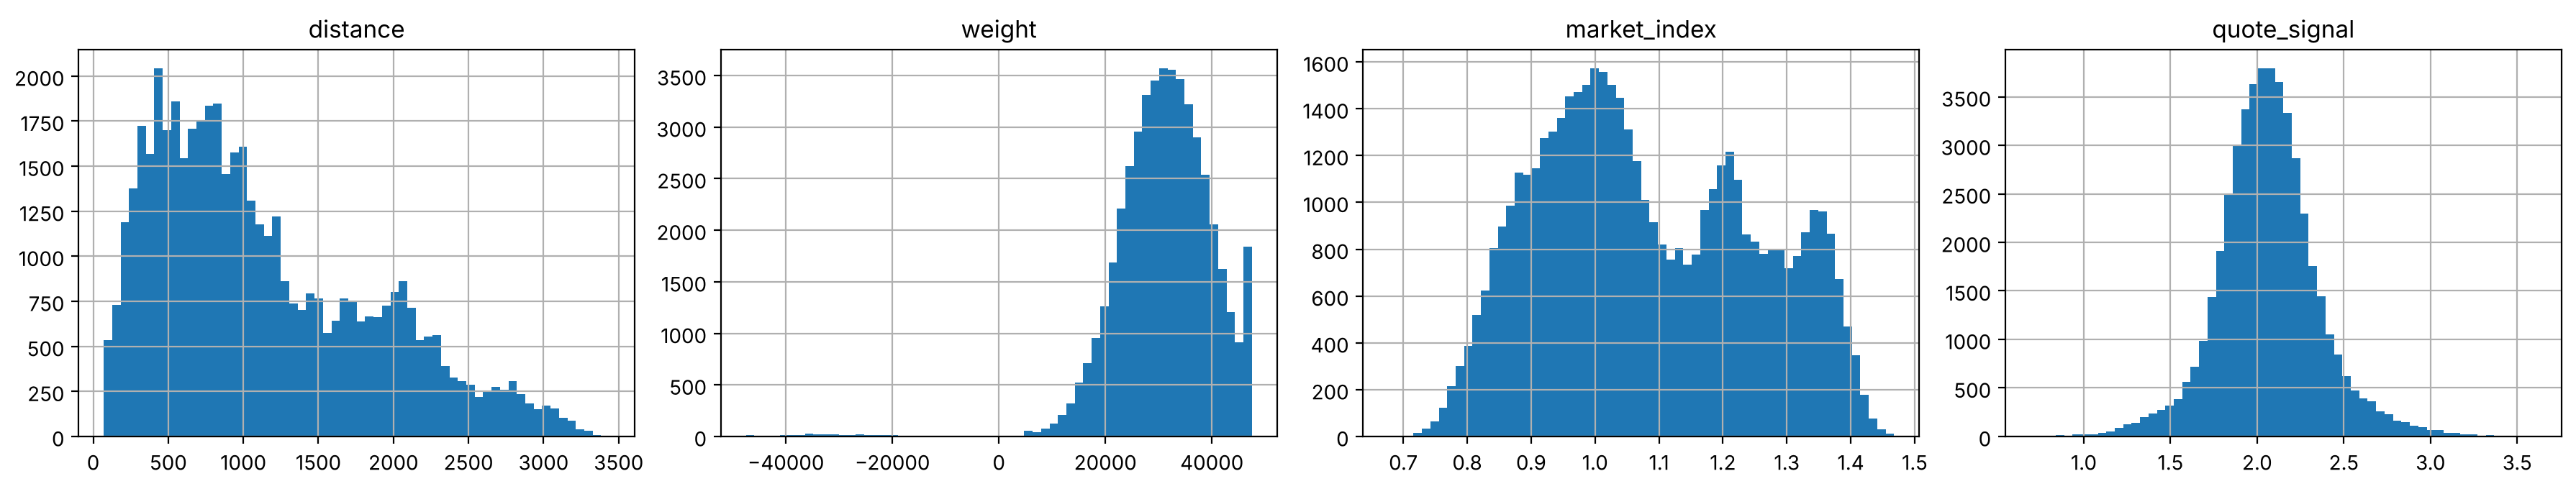

unique lanes: 4014


count    4014.000000
mean       11.958146
std         7.165047
min         1.000000
25%         6.000000
50%        10.000000
75%        16.000000
max        39.000000
Name: n, dtype: float64

,n,dist_min,dist_max,dist_std
lane,,,,
Reno -> Providence,2,3042.0,3173.4,92.913831
San Francisco -> Baltimore,2,3109.8,3238.9,91.287485
San Francisco -> Providence,5,3228.2,3439.8,88.533542
Los Angeles -> Providence,5,3090.8,3279.5,82.449603
Dayton -> San Francisco,3,2264.1,2416.0,78.827047
Detroit -> San Francisco,3,2312.1,2465.5,77.347614
Boston -> Albuquerque,5,2483.7,2639.5,75.496172
New York -> Reno,3,2634.7,2784.7,75.082643
Harrisburg -> San Francisco,9,2652.5,2875.3,68.200888


,pickup_lat,pickup_lon
pickup,,


In [4]:
for col in ["pickup", "delivery", "equipment"]:
    print(f"\n--- {col}: {train[col].nunique()} unique ---")
    display(train[col].value_counts(dropna=False).head(25))

display(train[["distance", "weight", "market_index", "quote_signal"]].describe())
display(train[["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]].describe())

fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for a, c in zip(ax, ["distance", "weight", "market_index", "quote_signal"]):
    train[c].hist(bins=60, ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

# Lanes
train["lane"] = train["pickup"] + " -> " + train["delivery"]
lane_stats = train.groupby("lane").agg(
    n=("lane", "size"),
    dist_min=("distance", "min"),
    dist_max=("distance", "max"),
    dist_std=("distance", "std"),
)
print("unique lanes:", len(lane_stats))
display(lane_stats["n"].describe())
display(lane_stats.sort_values("dist_std", ascending=False).head(10))

# Does one city name always map to one lat/lon?
display(train.groupby("pickup")[["pickup_lat", "pickup_lon"]].nunique().query("pickup_lat > 1 or pickup_lon > 1"))

## Rates over time
Training covers Jan–Oct 2025 and validation is Nov–Dec, so this is a forecasting problem.

train: 2025-01-01 00:00:00 -> 2025-10-31 00:00:00
val:   2025-11-01 00:00:00 -> 2025-12-31 00:00:00
dec:   2025-12-01 00:00:00 -> 2025-12-31 00:00:00


,n,mean,median
month,,,
2025-01,4918,2255.967048,1915.200
2025-02,4337,2273.804801,1994.250
2025-03,5036,2372.268092,2022.920
2025-04,4819,2372.162308,2044.240
2025-05,4913,2421.776342,2065.510
2025-06,4783,2497.030115,2120.220
2025-07,4912,2415.162030,2059.145
2025-08,4759,2338.407661,2015.730
2025-09,4670,2406.374013,2057.130


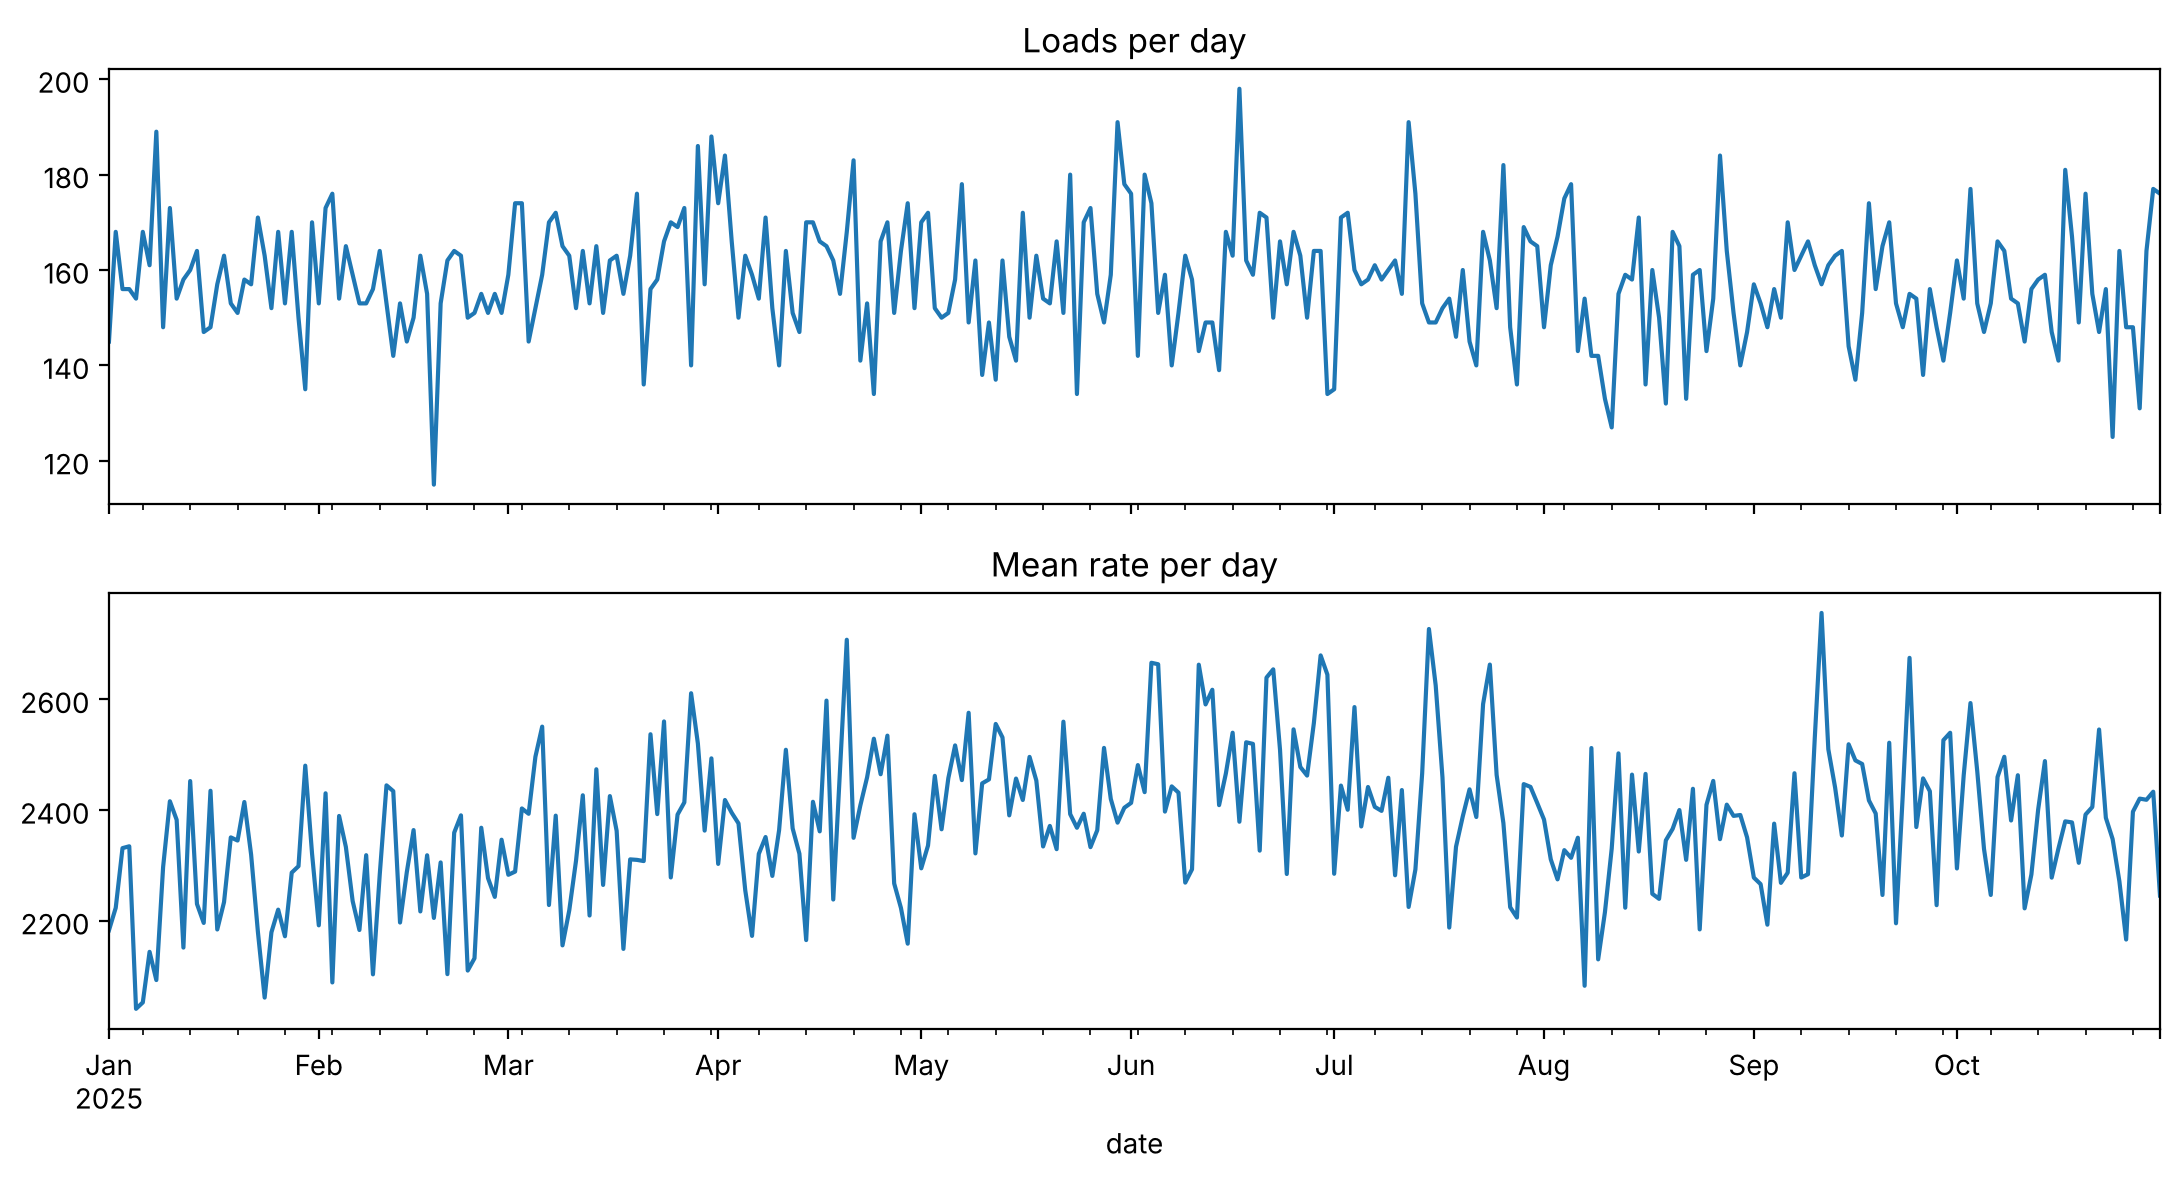

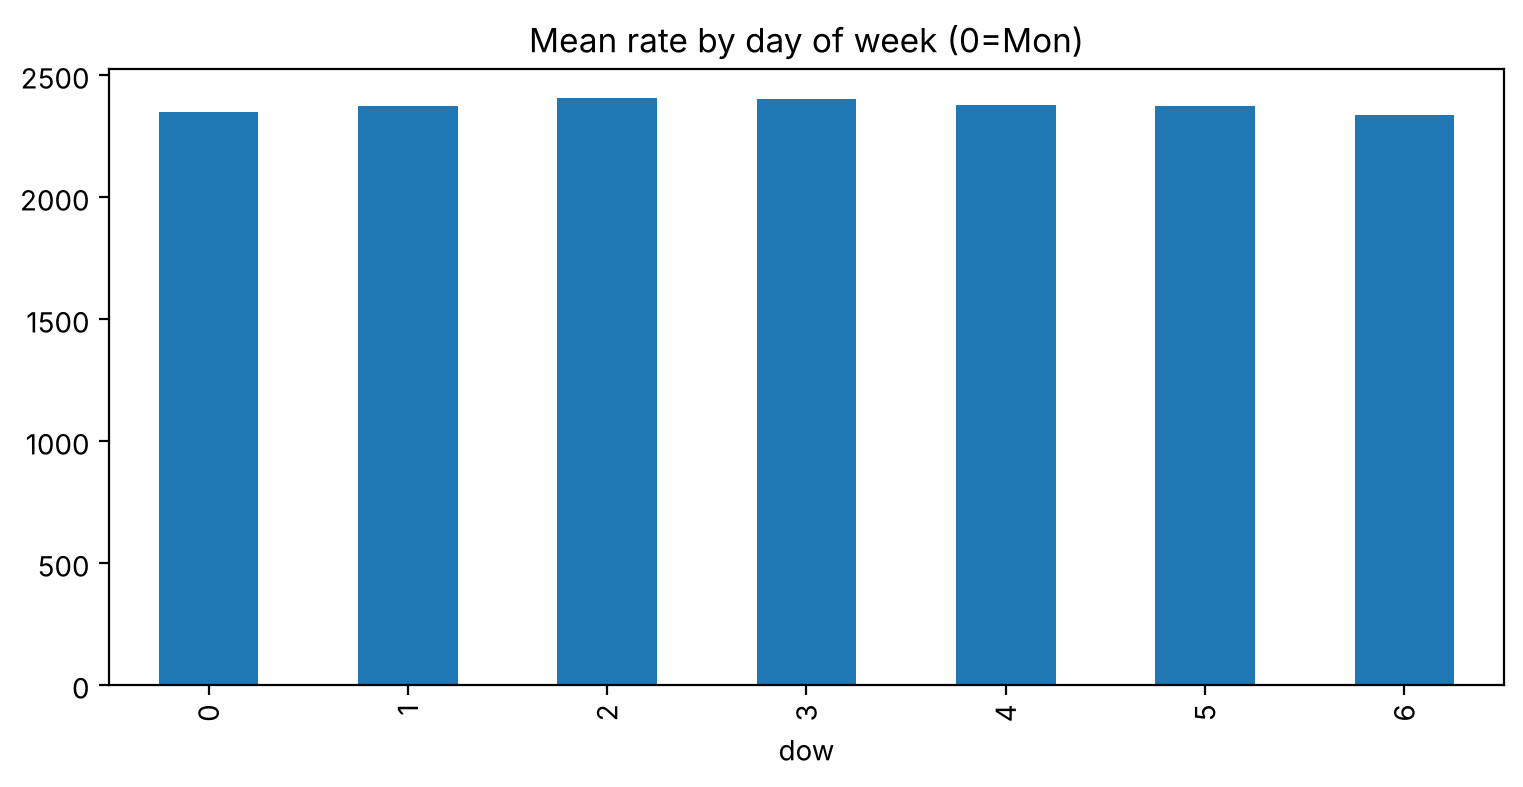

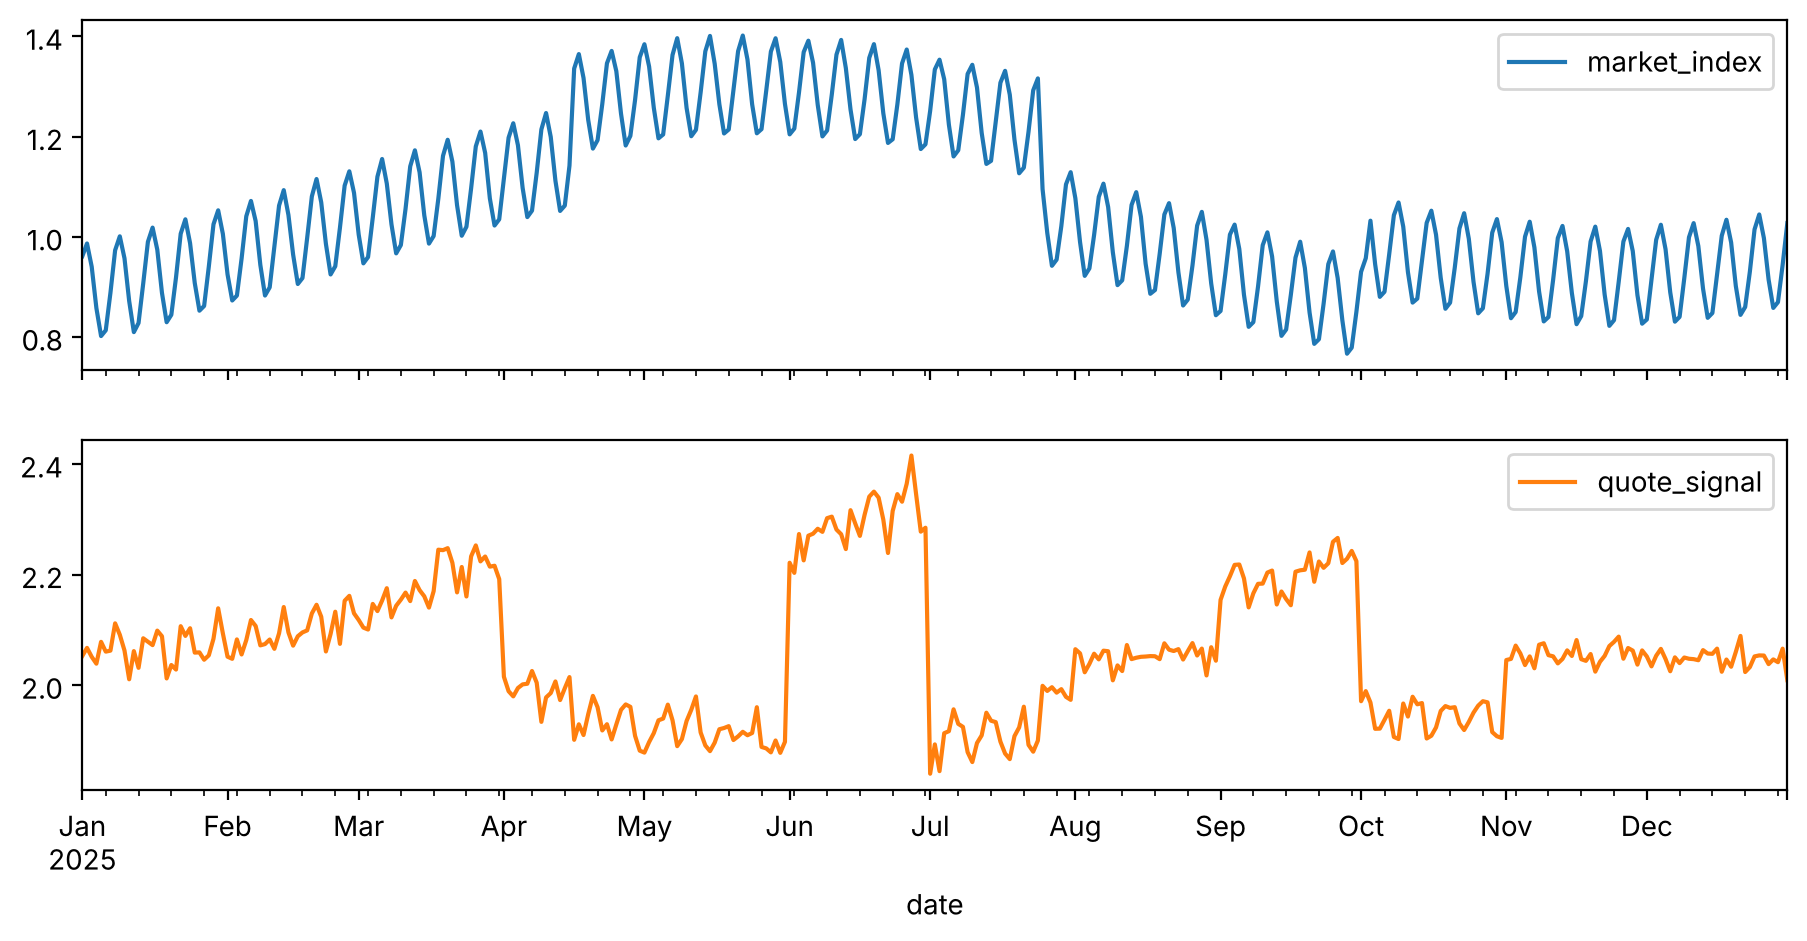

In [5]:
print("train:", train["date"].min(), "->", train["date"].max())
print("val:  ", val["date"].min(), "->", val["date"].max())
print("dec:  ", dec["date"].min(), "->", dec["date"].max())

train["month"] = train["date"].dt.to_period("M")
train["dow"] = train["date"].dt.dayofweek

display(train.groupby("month").agg(n=(TARGET, "size"), mean=(TARGET, "mean"), median=(TARGET, "median")))

daily = train.groupby("date").agg(n=(TARGET, "size"), mean_rate=(TARGET, "mean"))
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
daily["n"].plot(ax=ax[0], title="Loads per day")
daily["mean_rate"].plot(ax=ax[1], title="Mean rate per day")
plt.tight_layout(); plt.show()

train.groupby("dow")[TARGET].mean().plot(kind="bar", title="Mean rate by day of week (0=Mon)")
plt.show()

# Same view for market_index and quote_signal over time (train + val together)
both = pd.concat([train.assign(src="train"), val.assign(src="val")])
both.groupby("date")[["market_index", "quote_signal"]].mean().plot(subplots=True, figsize=(11, 5))
plt.show()

## What drives the rate
Distance dominates. Rate per mile falls with distance and differs by equipment.

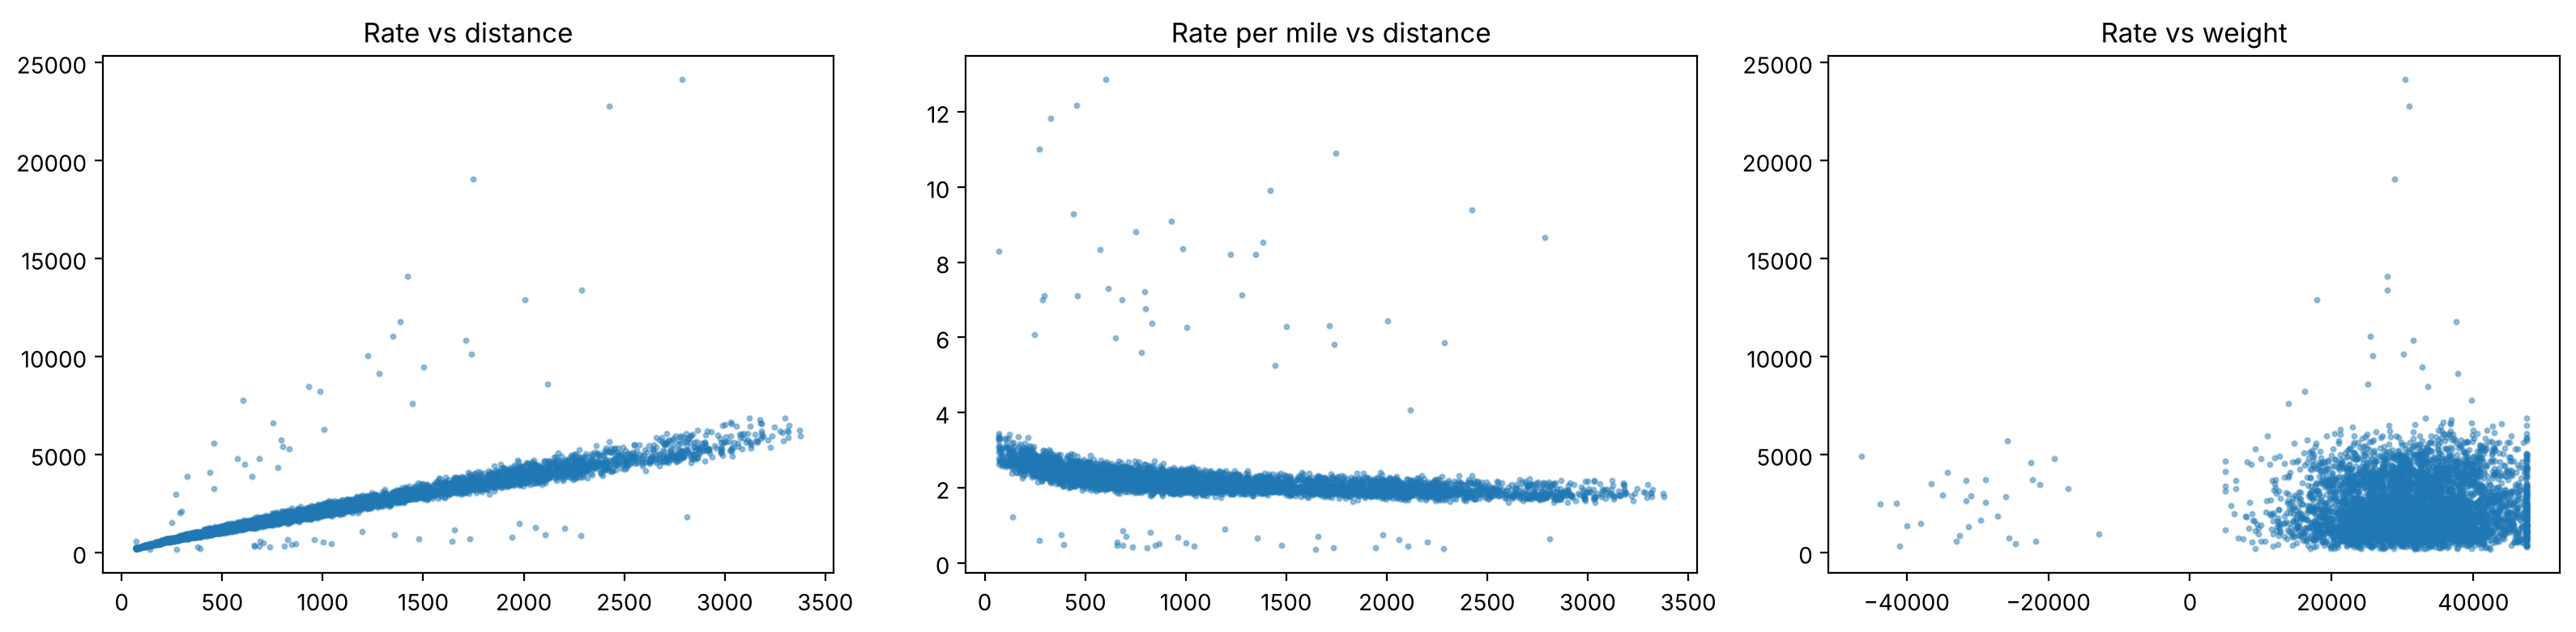

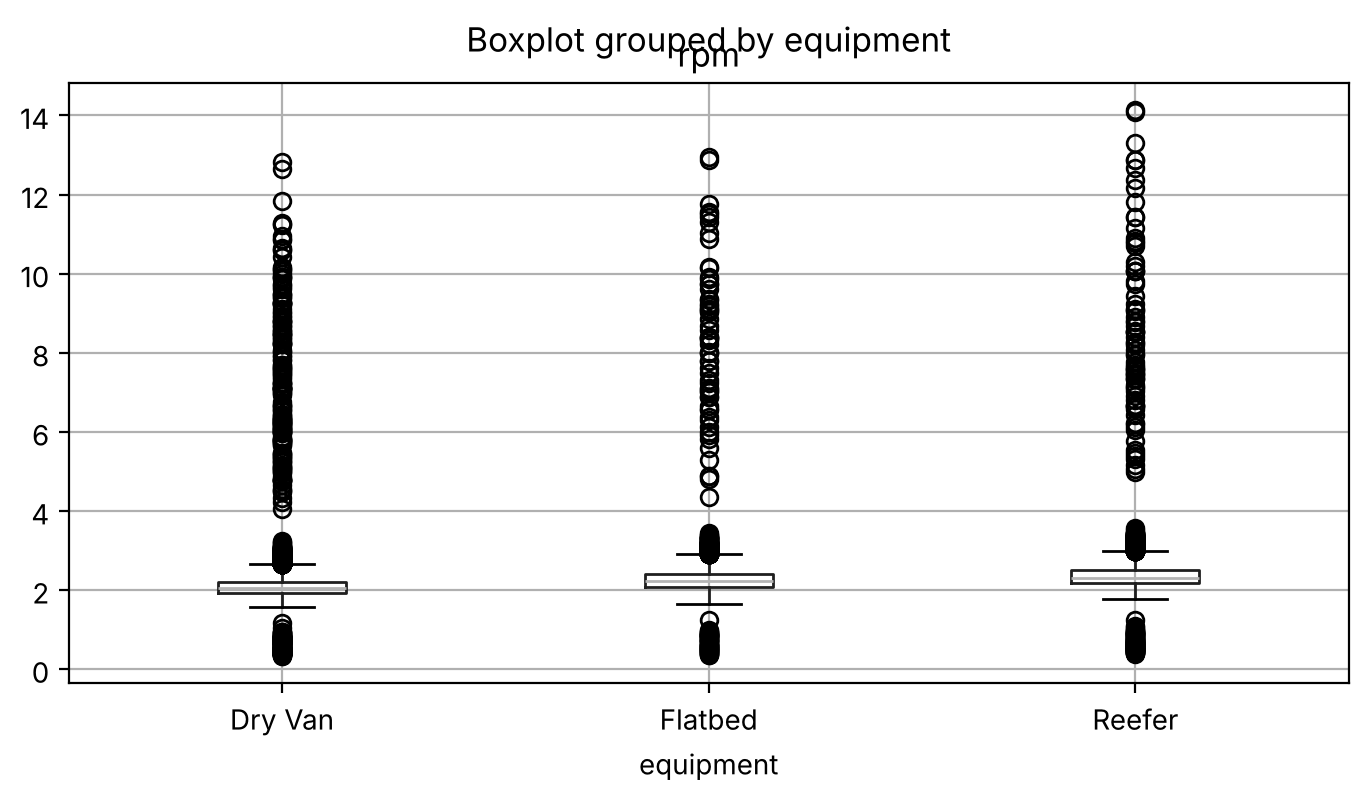

posted_rate                           rpm                    
                count         mean    median  count      mean    median
equipment                                                              
Dry Van         27202  2271.548686  1953.035  27202  2.115401  2.046203
Flatbed          8753  2445.087223  2076.810   8753  2.294729  2.219683
Reefer          12045  2553.636939  2196.670  12045  2.383376  2.311540

count    4014.000000
mean        2.213478
std         0.306690
min         0.483504
25%         2.020209
50%         2.144604
75%         2.334428
max         6.643753
Name: rpm, dtype: float64

,distance,weight,market_index,quote_signal,posted_rate,rpm
distance,1.00,0.00,-0.00,-0.06,0.91,-0.33
weight,0.00,1.00,-0.00,0.01,0.03,0.07
market_index,-0.00,-0.00,1.00,-0.07,0.03,0.08
quote_signal,-0.06,0.01,-0.07,1.00,-0.04,0.05
posted_rate,0.91,0.03,0.03,-0.04,1.00,0.00
rpm,-0.33,0.07,0.08,0.05,0.00,1.00


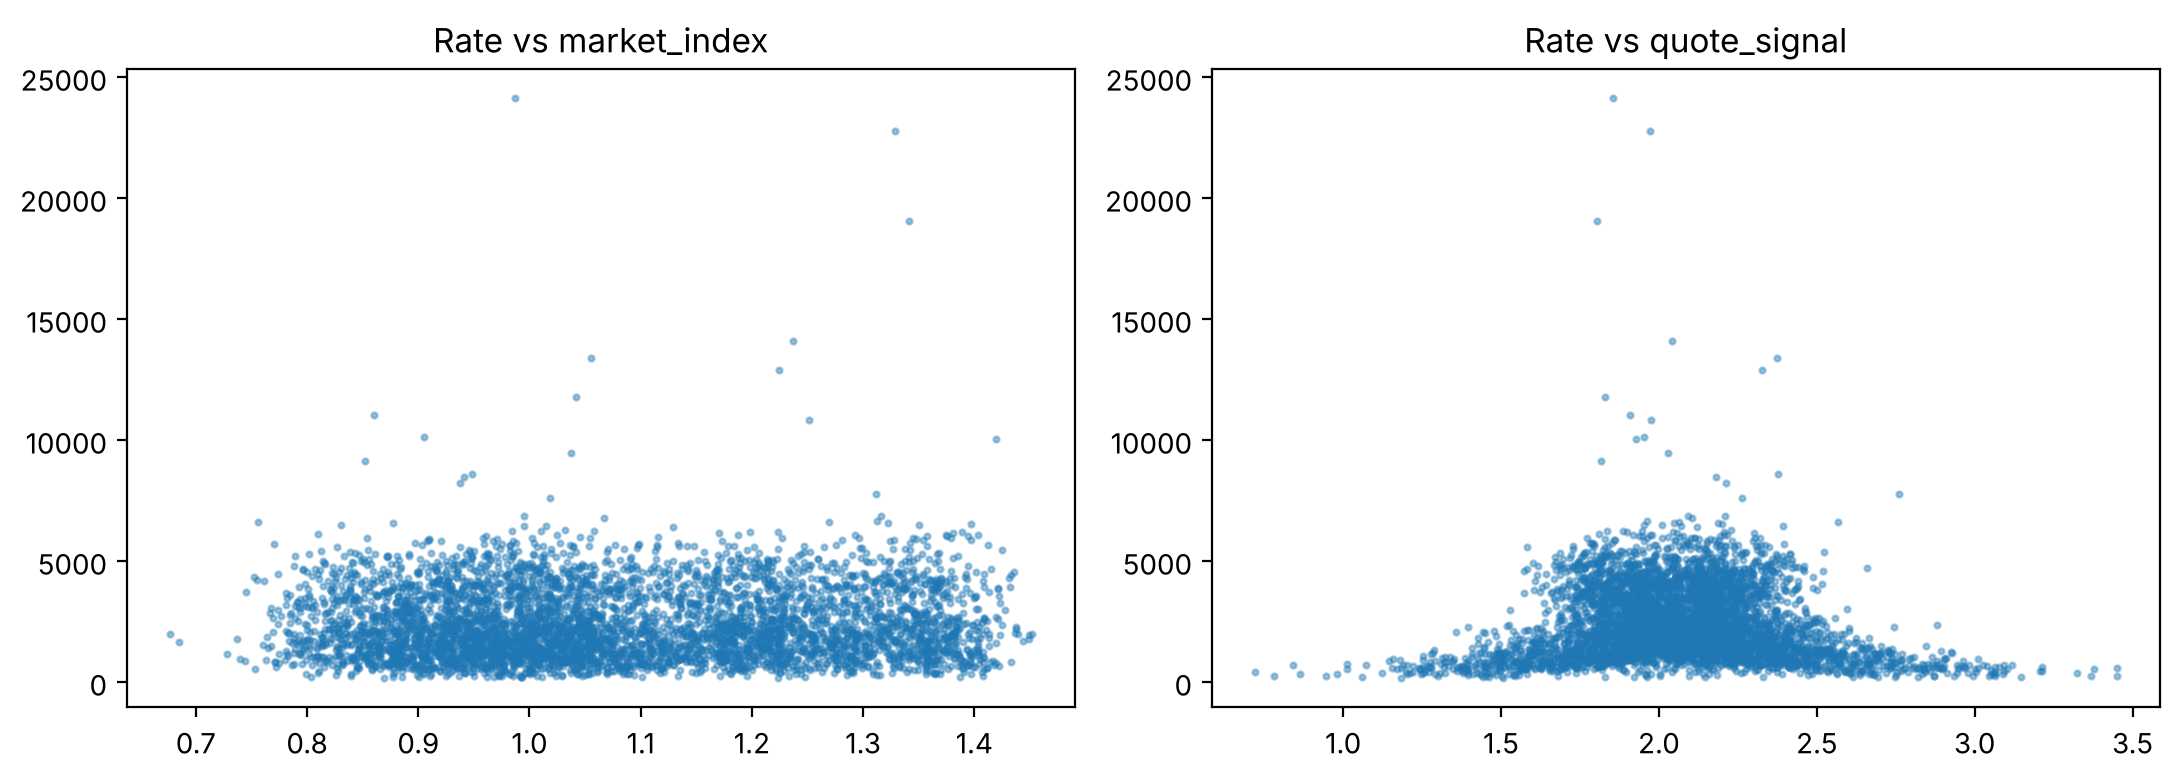

In [6]:
train["rpm"] = train[TARGET] / train["distance"]
sample = train.sample(5000, random_state=0)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(sample["distance"], sample[TARGET], s=4, alpha=.4); ax[0].set_title("Rate vs distance")
ax[1].scatter(sample["distance"], sample["rpm"], s=4, alpha=.4); ax[1].set_title("Rate per mile vs distance")
ax[2].scatter(sample["weight"], sample[TARGET], s=4, alpha=.4); ax[2].set_title("Rate vs weight")
plt.tight_layout(); plt.show()

train.boxplot(column="rpm", by="equipment", figsize=(8, 4)); plt.show()
display(train.groupby("equipment")[[TARGET, "rpm"]].agg(["count", "mean", "median"]))

display(train.groupby("lane")["rpm"].mean().describe())

num_cols = ["distance", "weight", "market_index", "quote_signal", TARGET, "rpm"]
display(train[num_cols].corr().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(sample["market_index"], sample[TARGET], s=4, alpha=.4); ax[0].set_title("Rate vs market_index")
ax[1].scatter(sample["quote_signal"], sample[TARGET], s=4, alpha=.4); ax[1].set_title("Rate vs quote_signal")
plt.tight_layout(); plt.show()

## Train vs validation
Checking for cities, lanes and feature ranges that only appear in validation.

pickup: 725 val rows with unseen value (6.04%); unseen values: 8
delivery: 722 val rows with unseen value (6.02%); unseen values: 8
equipment: 0 val rows with unseen value (0.00%); unseen values: 0
lane: 1461 val rows with unseen value (12.17%); unseen values: 736


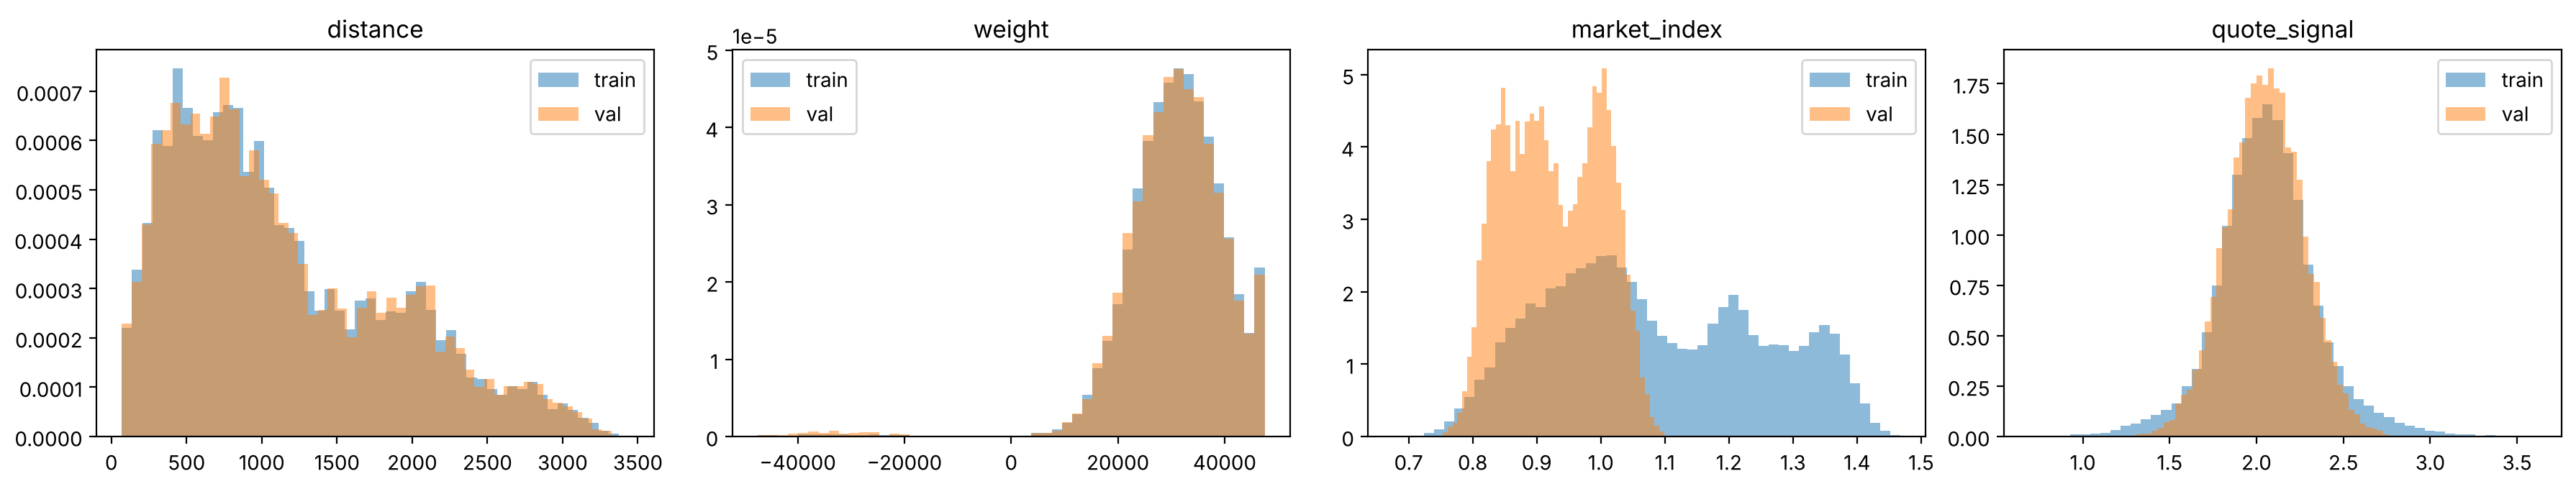

equipment
Dry Van    0.567
Reefer     0.251
Flatbed    0.182
Name: proportion, dtype: float64
equipment
Dry Van    0.565
Reefer     0.254
Flatbed    0.181
Name: proportion, dtype: float64


In [7]:
val["lane"] = val["pickup"] + " -> " + val["delivery"]

for col in ["pickup", "delivery", "equipment", "lane"]:
    unseen = ~val[col].isin(set(train[col]))
    print(f"{col}: {unseen.sum()} val rows with unseen value "
          f"({unseen.mean():.2%}); unseen values: {val.loc[unseen, col].nunique()}")

fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for a, c in zip(ax, ["distance", "weight", "market_index", "quote_signal"]):
    a.hist(train[c], bins=50, alpha=.5, density=True, label="train")
    a.hist(val[c], bins=50, alpha=.5, density=True, label="val")
    a.set_title(c); a.legend()
plt.tight_layout(); plt.show()

print(train["equipment"].value_counts(normalize=True).round(3))
print(val["equipment"].value_counts(normalize=True).round(3))

## The December chart input
The same Lexington → Fort Wayne load on every day of December, with no coordinates, `market_index` or `quote_signal`.

In [8]:
print(dec.drop(columns="date_raw").head(3))
print("columns in dec:", list(dec.columns))
print("columns the model sees in train:", list(train.columns))

mask = (train["pickup"] == "Lexington") & (train["delivery"] == "Fort Wayne")
print("Lexington->Fort Wayne loads in train:", mask.sum())
sub = train[mask]
display(sub.groupby("equipment")[TARGET].describe())
display(sub["distance"].describe())

# Similar loads: Dry Van, 300-420 miles, any lane
similar = train[(train["equipment"] == "Dry Van") & train["distance"].between(300, 420)]
display(similar[TARGET].describe())

      pickup    delivery  distance equipment  weight       date  \
0  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-01   
1  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-02   
2  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-03   

   predicted_rate  
0          816.10  
1          823.55  
2          829.08  
columns in dec: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate', 'date_raw']
columns the model sees in train: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate', 'date_raw', 'lane', 'month', 'dow', 'rpm']
Lexington->Fort Wayne loads in train: 32


,count,mean,std,min,25%,50%,75%,max
equipment,,,,,,,,
Dry Van,21.0,823.314286,46.151697,757.93,791.250,807.89,849.170,934.37
Flatbed,3.0,880.576667,37.889197,844.13,860.985,877.84,898.800,919.76
Reefer,8.0,934.940000,24.615236,901.41,916.670,934.50,949.615,973.75


count     32.000000
mean     363.668750
std        8.854612
min      346.300000
25%      358.150000
50%      362.300000
75%      368.150000
max      384.500000
Name: distance, dtype: float64

count    2020.000000
mean      854.236559
std       235.769224
min       144.920000
25%       783.760000
50%       833.970000
75%       897.442500
max      4613.610000
Name: posted_rate, dtype: float64

## Data-quality checks
Duplicates, sign-flipped and capped weights, missing values and rates that look wrong.

In [9]:
# Duplicates
print("dup load_id:", train["load_id"].duplicated().sum())
print("dup rows (excluding id):", train.drop(columns="load_id").duplicated().sum())

# Weights
print("negative weights:", (train["weight"] < 0).sum())
print("abs weight > 45000:", (train["weight"].abs() > 45000).sum())
print("weight == +/-47500:", (train["weight"].abs() == 47500).sum())

# Missingness patterns
for col in ["weight", "market_index"]:
    m = train[col].isna()
    print(f"\n{col} missing by month:")
    print(m.groupby(train["month"]).mean().round(4))
    print("missing by equipment:", m.groupby(train["equipment"]).mean().round(4).to_dict())
    print("mean rpm missing vs not:", train.loc[m, "rpm"].mean(), train.loc[~m, "rpm"].mean())
val_m = val["date"].dt.to_period("M")
print(val.assign(w=val["weight"].isna(), mi=val["market_index"].isna()).groupby(val_m)[["w", "mi"]].mean())

# Rate outliers
print(train.nlargest(10, TARGET)[["lane", "distance", "equipment", "weight", "date", TARGET, "rpm"]])
print(train.nsmallest(10, "rpm")[["lane", "distance", "equipment", TARGET, "rpm"]])

# Distance vs coordinates
def haversine(lat1, lon1, lat2, lon2):
    r = 3958.8
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2 * r * np.arcsin(np.sqrt(a))
train["hav"] = haversine(train.pickup_lat, train.pickup_lon, train.delivery_lat, train.delivery_lon)
print((train["distance"] / train["hav"]).describe())

# quote_signal / market_index drift over time
print(both.groupby(both["date"].dt.to_period("M"))[["market_index", "quote_signal"]].mean())

dup load_id: 0
dup rows (excluding id): 0
negative weights: 292
abs weight > 45000: 2364
weight == +/-47500: 1204

weight missing by month:
month
2025-01    0.0069
2025-02    0.0076
2025-03    0.0071
2025-04    0.0042
2025-05    0.0045
2025-06    0.0067
2025-07    0.0059
2025-08    0.0061
2025-09    0.0071
2025-10    0.0066
Freq: M, Name: weight, dtype: float64
missing by equipment: {'Dry Van': 0.0064, 'Flatbed': 0.0063, 'Reefer': 0.0058}
mean rpm missing vs not: 2.1576453877710984 2.215710071777107

market_index missing by month:
month
2025-01    0.0073
2025-02    0.0083
2025-03    0.0087
2025-04    0.0064
2025-05    0.0088
2025-06    0.0088
2025-07    0.0073
2025-08    0.0069
2025-09    0.0066
2025-10    0.0087
Freq: M, Name: market_index, dtype: float64
missing by equipment: {'Dry Van': 0.0074, 'Flatbed': 0.0083, 'Reefer': 0.0082}
mean rpm missing vs not: 2.1872724585183287 2.215567634078308
                w        mi
date                       
2025-11  0.014051  0.019705
2025-12 

## What I took from this

- **Time split is required.** Train is Jan–Oct, validation is Nov–Dec. A random split would let the model see the future.
- **Weights:** 292 negative (sign flips, same spread as the positives), ~1,200 stuck at exactly 47,500 (capped), 300 missing.
- **`market_index`:** 374 missing. It moves mostly with the date (within-day spread is small).
- **Bad rates:** about 1.4% of loads have a rate per mile far from normal, in two separate clusters. They look like entry errors, not real prices.
- **New cities:** 8 cities in validation never appear in training (about 12% of validation loads), so the model can't rely on city names.
- **December file:** has city names but no coordinates. Coordinates are fixed per city, so they can be looked up from the other files.